In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import math

In [2]:
df = pd.read_csv("titanic.csv")
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Basic exploration

In [3]:
df.shape

(891, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
print("\nData types:")
df.dtypes


Data types:


PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [8]:
print("\nBasic statistics:")
df.describe()


Basic statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## basic filling for NAN values, and fixing non-numeric values

In [9]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [ ]:
df.Embarked.fillna("S",inplace=True)

In [ ]:
df.Age.fillna(math.floor(df['Age'].mean()),inplace=True)

In [ ]:
df.drop("Cabin",axis=1,inplace=True)

In [ ]:
gender_mapping = {"female":0, "male":1}
df['Sex_Encodes'] = df['Sex'].map(gender_mapping)
df.drop("Sex",axis=1,inplace=True)

In [ ]:
df.info()

In [ ]:
# passenger ID, Name, Sibsp, parch, ticket, cabin, embarked
columns_to_drop= ['PassengerId','Name','SibSp','Parch','Ticket','Embarked_Q','Embarked_S']
df.drop(columns=columns_to_drop,inplace=True)

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Age          891 non-null    float64
 3   Fare         891 non-null    float64
 4   Sex_Encodes  891 non-null    int64  
dtypes: float64(2), int64(3)
memory usage: 34.9 KB


## Correlation Analysis

In [133]:
correlation = df.corr(numeric_only=True)

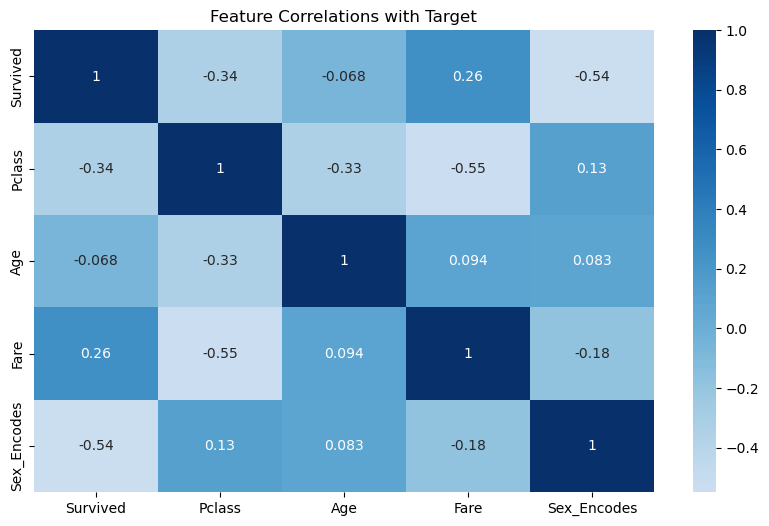

In [134]:
plt.figure(figsize=(10,6))
sb.heatmap(correlation, annot=True, cmap='Blues', center=0)
plt.title('Feature Correlations with Target')
plt.show()

In [135]:
target_correlations = correlation['Survived'].sort_values(ascending=False)
target_correlations


Survived       1.000000
Fare           0.257307
Age           -0.067814
Pclass        -0.338481
Sex_Encodes   -0.543351
Name: Survived, dtype: float64

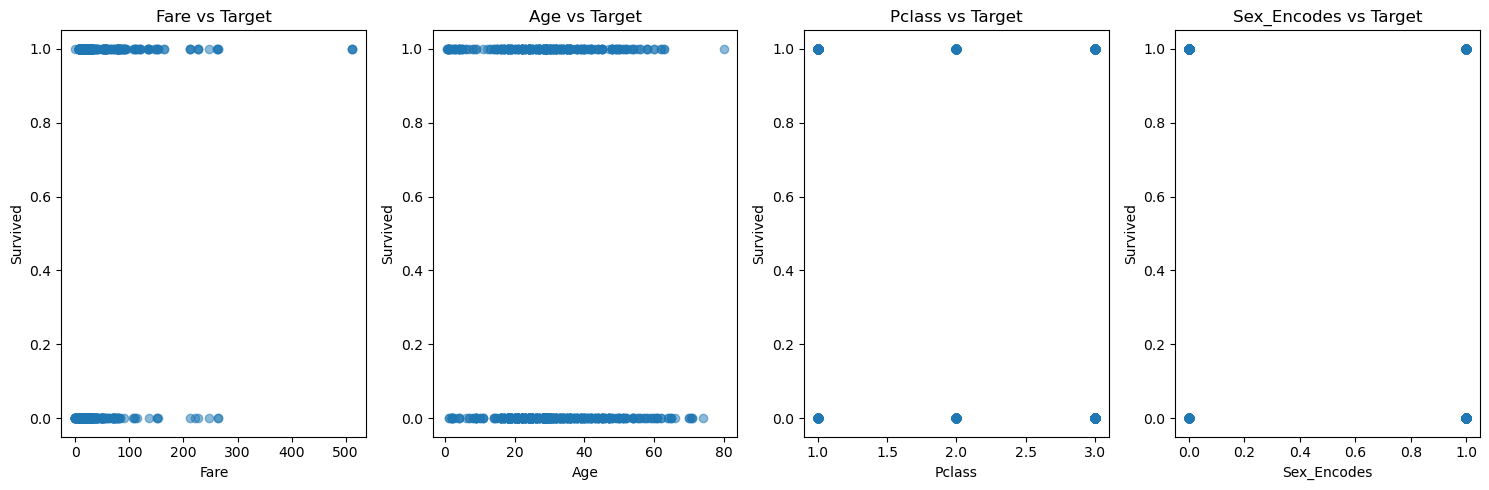

In [147]:
# Scatter plots for top correlated features
top_features = target_correlations.index[1:5]  # Skip target itself

fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for i, feature in enumerate(top_features):
    axes[i].scatter(df[feature], df['Survived'], alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Survived')
    axes[i].set_title(f'{feature} vs Target')
plt.tight_layout()
plt.show()

In [155]:
X = df.drop(df[['Survived']],axis=1)
y = df[['Survived']]h

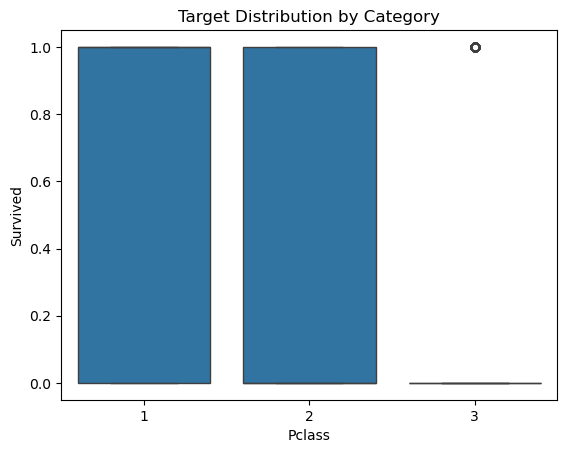

In [174]:
sb.boxplot(x='Pclass', y='Survived', data=df)
plt.title('Target Distribution by Category')
plt.show()

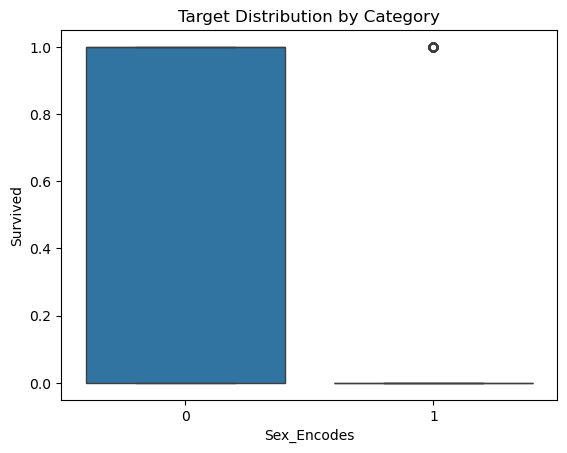

In [173]:
sb.boxplot(x='Sex_Encodes', y='Survived', data=df)
plt.title('Target Distribution by Category')
plt.show()

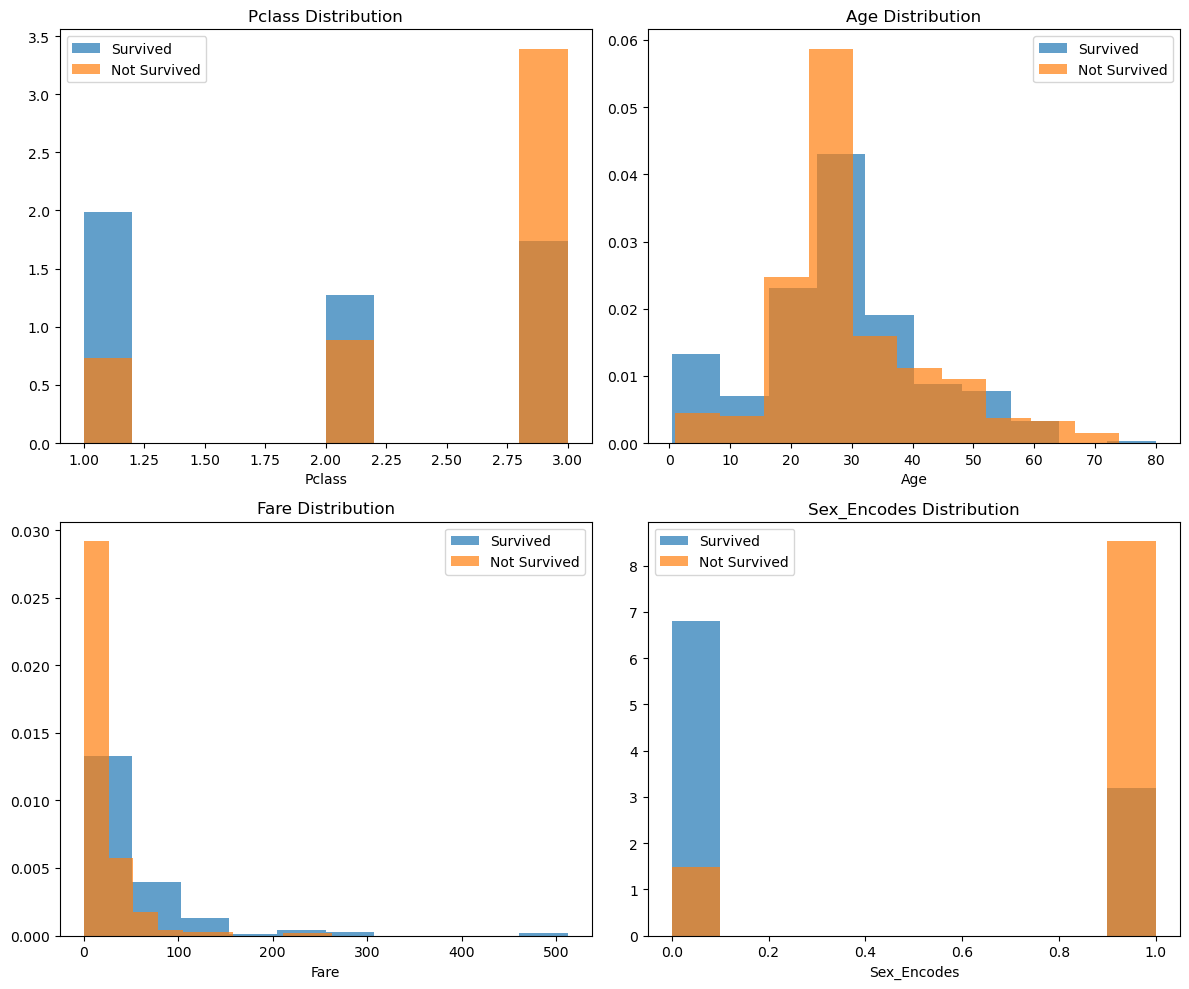

In [177]:
# Compare distributions of high vs low target values
high_target = df[df['Survived'] > df['Survived'].median()]
low_target = df[df['Survived'] <= df['Survived'].median()]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, feature in enumerate(['Pclass', 'Age', 'Fare', 'Sex_Encodes']):
    row, col = i // 2, i % 2
    axes[row, col].hist(high_target[feature], alpha=0.7, label='Survived', density=True)
    axes[row, col].hist(low_target[feature], alpha=0.7, label='Not Survived', density=True)
    axes[row, col].set_xlabel(feature)
    axes[row, col].legend()
    axes[row, col].set_title(f'{feature} Distribution')
plt.tight_layout()
plt.show()

## Train and test

In [181]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [179]:
from sklearn import tree
model = tree.DecisionTreeClassifier()

In [182]:
model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [184]:
model.score(X_test,y_test)

0.7653631284916201

In [188]:
from sklearn.linear_model import LogisticRegression
model2 = LogisticRegression()
model2.fit(X_train,y_train)

C:\Users\Humam\anaconda3\envs\dfds\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [187]:
model2.score(X_test,y_test)

0.7821229050279329

(712, 4)

In [1]:
import sys

print("Python version")
print(sys.version)
print("Version info.")
print(sys.version_info)

Python version
3.11.14 | packaged by conda-forge | (main, Oct 22 2025, 22:35:28) [MSC v.1944 64 bit (AMD64)]
Version info.
sys.version_info(major=3, minor=11, micro=14, releaselevel='final', serial=0)
